# 2 - Feature engineering

This notebook turns the cleaned daily observations from notebook 1 into the
model-ready **feature table**: one row per city and day, with 42 input features
and nine targets (three forecasts, each 1, 2 and 3 days ahead).

It uses `climatelens.features.build_features`, the same function the cloud
pipeline runs after every daily ingest (`climatelens features`).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from climatelens.config import get_settings
from climatelens.data import read_raw
from climatelens.features import (
    ALL_TARGETS,
    DELTA_FIELDS,
    FEATURE_COLUMNS,
    FEATURE_FIELDS,
    HORIZONS,
    ROLLING_FIELDS,
    ROLLING_WINDOWS,
    TARGETS,
    build_features,
    feature_report,
    latest_rows,
    target_name,
)

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIGURES = Path("notebooks/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

raw = read_raw(get_settings().raw_uri)
features = build_features(raw)
print(f"raw: {raw.shape}  ->  feature table: {features.shape}")
print(f"{len(FEATURE_COLUMNS)} feature columns, {len(ALL_TARGETS)} target columns")

raw: (13656, 20)  ->  feature table: (13656, 56)
42 feature columns, 9 target columns


## 2.1 Targets

Row *t* holds features computed from data up to and including day *t*, and the
targets observed *h* days later. DWD publishes a day's data on the following day,
so when the service forecasts *tomorrow* its newest observation is usually
yesterday: the dashboard therefore uses the **2-day** model (3-day if DWD is late).

In [2]:
report = feature_report(features)
target_info = {
    "target_frost": ("Frost", "agriculture / gardens", "classification", "min air temp 2 m < 0 °C"),
    "target_solar_kwh_m2": ("Sunshine", "solar energy", "regression", "global radiation, kWh/m²"),
    "target_wind_speed": ("Wind", "outdoors", "regression", "mean wind speed, m/s"),
}
rows = []
for base in TARGETS:
    label, angle, kind, definition = target_info[base]
    for h in HORIZONS:
        col = target_name(base, h)
        rows.append(
            {
                "forecast": label,
                "angle": angle,
                "type": kind,
                "definition": definition,
                "days ahead": h,
                "column": col,
                "rows with target": report.target_rows[col],
                "last target date": report.target_last_date[col],
            }
        )
pd.DataFrame(rows)

,forecast,angle,type,definition,days ahead,column,rows with target,last target date
0,Frost,agriculture / gardens,classification,min air temp 2 m < 0 °C,1,target_frost,13643,2026-10-15
1,Frost,agriculture / gardens,classification,min air temp 2 m < 0 °C,2,target_frost_h2,13631,2026-10-14
2,Frost,agriculture / gardens,classification,min air temp 2 m < 0 °C,3,target_frost_h3,13619,2026-10-13
3,Sunshine,solar energy,regression,"global radiation, kWh/m²",1,target_solar_kwh_m2,12100,2026-07-30
4,Sunshine,solar energy,regression,"global radiation, kWh/m²",2,target_solar_kwh_m2_h2,12090,2026-07-29
5,Sunshine,solar energy,regression,"global radiation, kWh/m²",3,target_solar_kwh_m2_h3,12080,2026-07-28
6,Wind,outdoors,regression,"mean wind speed, m/s",1,target_wind_speed,13426,2026-10-15
7,Wind,outdoors,regression,"mean wind speed, m/s",2,target_wind_speed_h2,13414,2026-10-14
8,Wind,outdoors,regression,"mean wind speed, m/s",3,target_wind_speed_h3,13402,2026-10-13


In [3]:
print(f"frost occurs on {report.frost_positive_rate:.1%} of days (1 day ahead)")
print("rows without a target are kept in the table but excluded for that target only")

frost occurs on 14.9% of days (1 day ahead)
rows without a target are kept in the table but excluded for that target only


## 2.2 Feature groups

All features use data **up to the forecast day only**. Each city is first placed on
a complete daily calendar, so a missing day becomes "unknown" instead of silently
pairing a day with the day after next.

In [4]:
groups = {
    "Same-day measurements": list(FEATURE_FIELDS),
    "Diurnal range": ["temperature_air_range_2m"],
    "Previous day (lag 1)": [f"{f}_lag1" for f in FEATURE_FIELDS],
    "Day-over-day change": [f"{f}_delta1" for f in DELTA_FIELDS],
    "Trailing averages": [f"{f}_mean{w}d" for f in ROLLING_FIELDS for w in ROLLING_WINDOWS],
    "Precipitation sum": ["precipitation_height_sum3d"],
    "Calendar": ["day_of_year_sin", "day_of_year_cos", "month"],
    "Station": ["station_latitude", "station_longitude", "station_elevation_m"],
}
assert sorted(sum(groups.values(), [])) == sorted(FEATURE_COLUMNS)
pd.DataFrame(
    [{"group": g, "count": len(cols), "features": ", ".join(cols)} for g, cols in groups.items()]
    + [{"group": "Total", "count": len(FEATURE_COLUMNS), "features": ""}]
)

,group,count,features
0,Same-day measurements,10,"temperature_air_mean_2m, temperature_air_min_2..."
1,Diurnal range,1,temperature_air_range_2m
2,Previous day (lag 1),10,"temperature_air_mean_2m_lag1, temperature_air_..."
3,Day-over-day change,4,"temperature_air_mean_2m_delta1, temperature_ai..."
4,Trailing averages,10,"temperature_air_mean_2m_mean3d, temperature_ai..."
5,Precipitation sum,1,precipitation_height_sum3d
6,Calendar,3,"day_of_year_sin, day_of_year_cos, month"
7,Station,3,"station_latitude, station_longitude, station_e..."
8,Total,42,


Why these features:

* **same day and previous day** - weather is persistent; today's values are the
  strongest single signal,
* **changes** - a falling temperature or pressure (tendency) announces a change,
* **3- and 7-day means** - the recent regime, less noisy than one day,
* **calendar** - sine and cosine of the day of year encode the season smoothly
  (31 December is next to 1 January),
* **station** - location and elevation let one model serve all 12 cities.

### Worked example: Berlin, mean temperature

In [5]:
cols = [
    "date",
    "temperature_air_mean_2m",
    "temperature_air_mean_2m_lag1",
    "temperature_air_mean_2m_delta1",
    "temperature_air_mean_2m_mean3d",
    "temperature_air_mean_2m_mean7d",
    "temperature_air_min_2m",
    "target_frost",
    "target_frost_h2",
]
features.loc[features["city"] == "berlin", cols].iloc[-10:].round(2)

,date,temperature_air_mean_2m,temperature_air_mean_2m_lag1,temperature_air_mean_2m_delta1,temperature_air_mean_2m_mean3d,temperature_air_mean_2m_mean7d,temperature_air_min_2m,target_frost,target_frost_h2
1128,2026-10-07,15.2,14.4,0.8,14.83,15.26,8.5,0.0,0.0
1129,2026-10-08,12.5,15.2,-2.7,14.03,14.43,9.4,0.0,0.0
1130,2026-10-09,10.8,12.5,-1.7,12.83,13.90,9.1,0.0,0.0
1131,2026-10-10,13.5,10.8,2.7,12.27,13.66,9.9,0.0,0.0
1132,2026-10-11,10.4,13.5,-3.1,11.57,13.10,8.8,0.0,0.0
1133,2026-10-12,9.2,10.4,-1.2,11.03,12.29,3.6,0.0,0.0
1134,2026-10-13,10.0,9.2,0.8,9.87,11.66,1.2,0.0,0.0
1135,2026-10-14,12.7,10.0,2.7,10.63,11.30,6.7,0.0,0.0
1136,2026-10-15,11.0,12.7,-1.7,11.23,11.09,5.1,0.0,NaN
1137,2026-10-16,11.9,11.0,0.9,11.87,11.24,4.0,NaN,NaN


The last rows have no target yet (the future is unknown); the very last row per
city is exactly the input the service uses for its live forecast.

In [6]:
latest_rows(features)[["city", "date", *FEATURE_COLUMNS[:4]]]

,city,date,temperature_air_mean_2m,temperature_air_min_2m,temperature_air_max_2m,temperature_air_min_0_05m
0,berlin,2026-10-16,11.9,4.0,19.8,0.9
1,bremen,2026-10-16,15.7,11.5,21.0,10.6
2,cologne,2026-10-16,16.5,11.8,22.9,10.3
3,dresden,2026-10-16,12.0,6.2,19.0,4.8
4,essen,2026-10-16,16.4,11.2,21.6,11.1
5,frankfurt,2026-10-16,11.9,5.7,20.8,4.6
6,hamburg,2026-10-16,15.5,11.8,21.1,11.2
7,hannover,2026-10-16,15.7,10.6,21.5,7.4
8,leipzig,2026-10-16,12.8,7.4,20.0,4.5
9,munich,2026-10-16,13.7,7.7,21.8,6.2


## 2.3 Missing values

Missing feature values are **not imputed**; LightGBM handles them natively. They
come from the few days a station did not report a value (mostly wind and cloud
cover) and from the first days of the history, where lags and means have no past.

In [7]:
nulls = pd.Series(report.feature_null_pct).sort_values(ascending=False)
print(f"{len(nulls)} of {len(FEATURE_COLUMNS)} features have any missing values")
nulls.head(10).rename("% missing").to_frame().T

36 of 42 features have any missing values


,wind_speed_delta1,wind_speed_lag1,wind_gust_max_lag1,wind_speed,wind_speed_mean3d,wind_speed_mean7d,wind_gust_max,cloud_cover_total_lag1,cloud_cover_total,cloud_cover_total_mean3d
% missing,1.95,1.68,1.65,1.6,1.58,1.57,1.56,1.08,0.99,0.97


## 2.4 Which features relate to which target?

Rank correlation (Spearman) between every feature and each 1-day-ahead target -
a first, model-free view of the signal. The model itself also learns non-linear
effects and interactions.

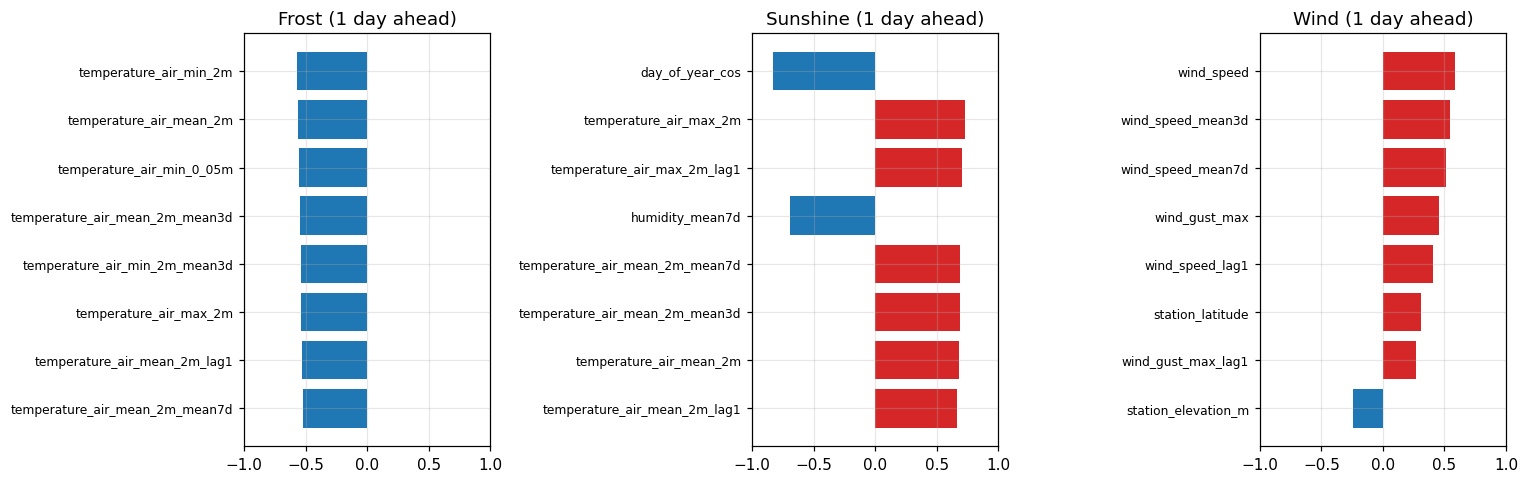

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, base in zip(axes, TARGETS, strict=True):
    corr = features[[*FEATURE_COLUMNS, base]].corr(method="spearman")[base].drop(base)
    top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(8)[::-1]
    ax.barh(top.index, top.values, color=np.where(top.values > 0, "tab:red", "tab:blue"))
    ax.set_title(target_info[base][0] + " (1 day ahead)")
    ax.set_xlim(-1, 1)
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "feature_correlations.png", bbox_inches="tight")
plt.show()

As expected: frost depends on current and recent temperatures, solar energy on
the season (day of year) and cloud cover, and wind mostly on the current and
recent wind.

## 2.5 Quality checks

### No look-ahead

A feature for day *t* must never use data from after *t*. Test: change every
measurement on the **last** day, rebuild the table, and confirm that no feature of
any earlier day changes. (The same check runs in the automated test suite.)

In [9]:
last_day = raw["date"].max()
changed = raw.copy()
measured = [f for f in FEATURE_FIELDS if f in changed.columns]
changed.loc[changed["date"] == last_day, measured] += 10.0

before = features.loc[features["date"] < last_day, list(FEATURE_COLUMNS)].reset_index(drop=True)
rebuilt = build_features(changed)
after = rebuilt.loc[rebuilt["date"] < last_day, list(FEATURE_COLUMNS)]
after = after.reset_index(drop=True)
pd.testing.assert_frame_equal(before, after)
print(
    f"OK - changing {last_day:%Y-%m-%d} left all {before.size:,} earlier feature values unchanged"
)

OK - changing 2026-10-16 left all 573,048 earlier feature values unchanged


### Gaps stay gaps

If a day is missing, the next day's "previous day" feature must be unknown - not
the value from two days earlier.

In [10]:
berlin = raw[raw["city"] == "berlin"]
gap_day = pd.Timestamp(berlin["date"].iloc[-5]).as_unit("ns")
one_day = pd.Timedelta(1, unit="D")
with_gap = build_features(berlin[berlin["date"] != gap_day])
next_day = with_gap.loc[with_gap["date"] == gap_day + one_day]
print(f"day removed: {gap_day:%Y-%m-%d}")
print("previous-day temperature on the next day:", next_day["temperature_air_mean_2m_lag1"].item())
print(
    "1-day-ahead frost target on the day before the gap:",
    with_gap.loc[with_gap["date"] == gap_day - one_day, "target_frost"].item(),
)

day removed: 2026-10-12
previous-day temperature on the next day: nan
1-day-ahead frost target on the day before the gap: nan


## Summary

| Step | Result |
|---|---|
| Rows | one per city and day, from the full stored history |
| Inputs | 42 features in 8 groups, from 10 near-complete measured fields |
| Targets | frost (classification), solar energy and wind (regression), each 1-3 days ahead |
| Missing values | kept as missing; rows without a target excluded per target |
| Leakage | no feature uses data after its day (checked above and in the test suite) |

In production the table is rebuilt after every daily ingest and stored as
`gs://climatelens-iu-data/features/features.parquet` (about 1 MB). Notebook 3
trains and evaluates the models on it.